# W07A - Pair distance histogram

In this exercise you will use the pair distance histogram to group various microstates of particles
in a discretized space

In [2]:
import numpy as np
import matplotlib.pyplot as plt

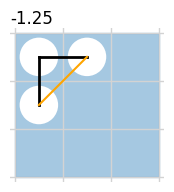

In [3]:
from week07 import make_microstate_factory

MicroState = make_microstate_factory(L=3, N=3)

fig, ax = plt.subplots(figsize=(2,2))
m = MicroState(1)
m.plot(ax, label='Energy')

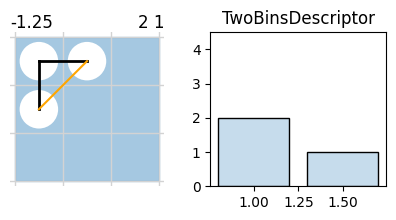

In [4]:
from week07 import DescriptorBase
from scipy.spatial.distance import pdist

class TwoBinsDescriptor(DescriptorBase):

    centers = [1, 1.5]
    ylim = [0, 4.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist, _ = np.histogram(dist_vector, self.edges)
        return hist.tolist()   # returns the bin counts

descriptor_method_2d = TwoBinsDescriptor()
# for m.pos, the descriptor would return [2,1], i.e. 2 bonds of length 1, 1 bond of length sqrt(2)


MicroState = make_microstate_factory (N=3, L=3, descriptor_method = descriptor_method_2d)


fig, axes = plt.subplots(1,2, figsize=(5,2))
m = MicroState(1)
m.plot(axes[0], label='Dual') # or 'Descriptor' for just the descriptor (no Energy)
m.plot_descriptor(axes[1])

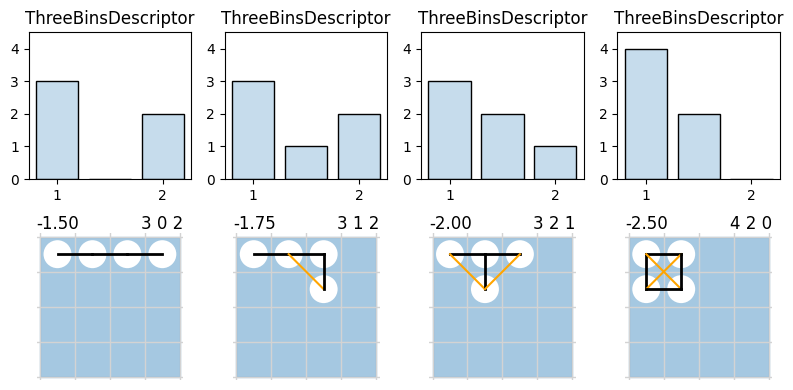

In [5]:
class ThreeBinsDescriptor(DescriptorBase):

    centers = [1, 1.5, 2]
    ylim = [0, 4.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist, _ = np.histogram(dist_vector, self.edges)
        return hist.tolist()   # returns the bin counts

descriptor_method_3bins = ThreeBinsDescriptor()

MicroState = make_microstate_factory (N=4, L=4, descriptor_method = descriptor_method_3bins)

fig, axes = plt.subplots(2,4, figsize=(8,4))

for i, idx in zip(range(4), [0, 3, 2, 25]):
    m = MicroState(idx)
    m.plot(axes[1][i], label='Dual')
    m.plot_descriptor(axes[0][i])
fig.tight_layout()

### Task 4

Find some states with the same descriptor and plot them. Is the descriptor unique?

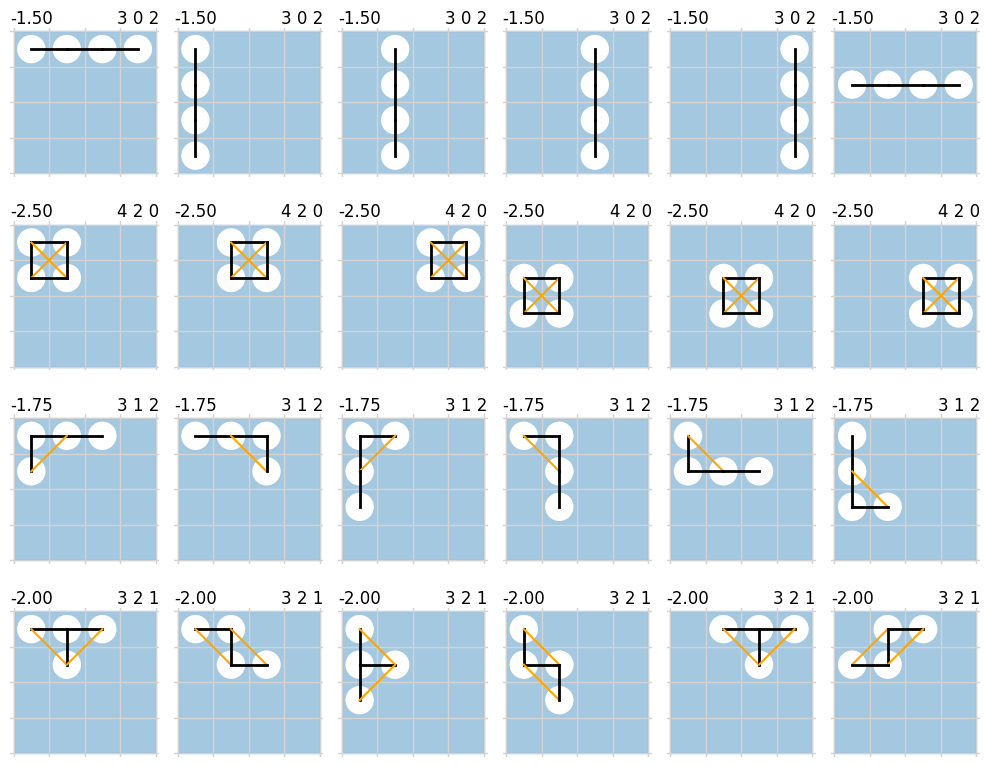

In [6]:
unique_descriptors = [
    [3, 0, 2],   # 3 of pairwise distance around d=1, 2 around d=1.5, 1 around d=2
    [4, 2, 0],
    [3, 1, 2],
    [3, 2, 1],
]

fig, axes = plt.subplots(4,6, figsize=(10,8))

for row, descriptor in enumerate(unique_descriptors):
    unique_microstates = []
    for i in range(1820):
        m = MicroState(i)
        if m.descriptor == descriptor:
            # print('Found descriptor at idx:', i)
            unique_microstates.append(m)
        if len(unique_microstates) == 6:
            break

    for ms, ax in zip(unique_microstates, axes[row]):
        ms.plot(ax, label='Dual')

fig.tight_layout()

The discriptor is not unique. It can descripes at least one system and sometimes more, but they share the same energy.

# W07B - Metropolis Monte Carlo

In [63]:
class MonteCarlo():
    def __init__(self, system, initial_state, kT=0.15):
        self.system = system
        self.kT = kT
        self.initial_state = initial_state
        self.states = [self.initial_state]

    def run(self, Nsamples=1000):
        print('Running MMC for', Nsamples, 'steps.')
        self.state = self.initial_state
        self.opt_m = self.state
        
        for _ in range(Nsamples):
            trail = self.system(self.state.i)
            trail.shuffle_one_particle()
            de = (trail.energy - self.state.energy)

            acceptance_probability = min(1, np.exp(-de / self.kT))
            if np.random.rand() < acceptance_probability:
                self.state = trail
                self.states.append(self.state)
                if self.state.energy < self.opt_m.energy:
                    self.opt_m = self.state

        print('Optimal system energy:', self.opt_m.energy)

    def plot(self, axes):
        print('Plotting optimal structure:')
        self.initial_state.plot(axes[0])
        self.opt_m.plot(axes[1], label='Dual')
        

Running MMC for 1000 steps.
Optimal system energy: -11.5
Plotting optimal structure:


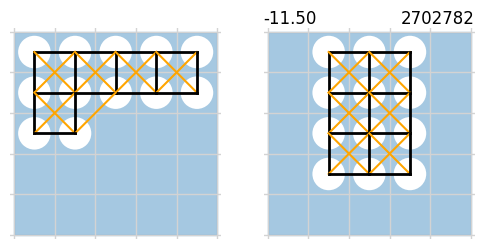

In [ ]:
MicroState = make_microstate_factory(N=12, L=5)

m = MicroState(0)

fig, axes = plt.subplots(1,2,figsize=(6,3))

mmc = MonteCarlo(MicroState, m)
mmc.run(Nsamples=1000)
mmc.plot(axes)

### Task 2 

Metropolis Monte Carlo Markov chain, plot the set of structures along the trajectory from optimal structure with distinct descriptors (energies)

Running MMC for 100 steps.
Optimal system energy: -11.5
[-11.5, -11.25, -11.0, -10.75, -9.75, -10.25, -10.5]


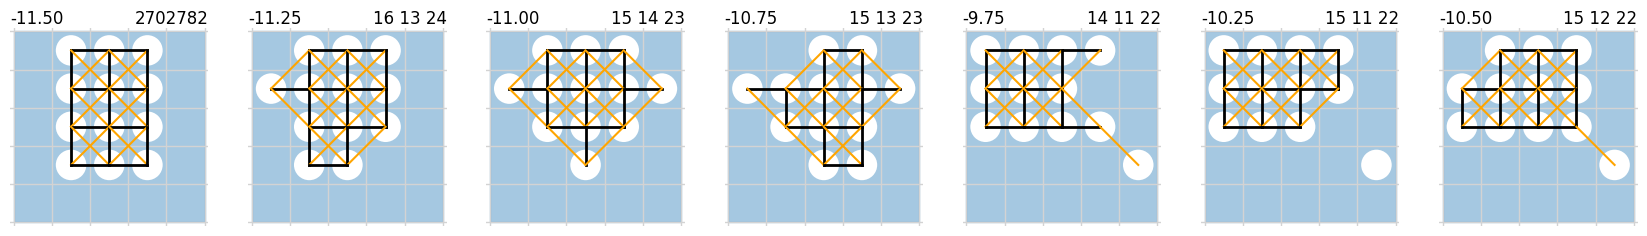

In [106]:
# class MonteCarloMarkovChain(MonteCarlo):
#     def plot_chain(self, axes, states):
#         for i, state in enumerate(states):
#             state.plot(axes[i], label='Dual')

opt_m = mmc.opt_m
mcc_markov = MonteCarlo(MicroState, opt_m, kT=0.3)
mcc_markov.run(100)

descriptors = []
descriptors_states = []

for state in mcc_markov.states:
    if state.energy not in descriptors:
        descriptors.append(state.energy)
        descriptors_states.append(state)
    if len(descriptors) >= 8:
        break

fig_length = len(descriptors)
fig, axes = plt.subplots(1, fig_length, figsize=(3*fig_length, 3))

print(descriptors)
for i, state in enumerate(descriptors_states):
    state.plot(axes[i], label='Dual')
# mcc_markov.plot_chain(axes, descriptors_states)

### Task 3

Repeat with three-bin pair-distance vector as descriptor, such that the same energy can appear several times.

Running MMC for 100 steps.
Optimal system energy: -11.5
[[17, 12, 24], [16, 13, 23], [16, 12, 22], [16, 12, 23], [16, 13, 24], [15, 12, 23], [15, 12, 22], [15, 13, 24]]


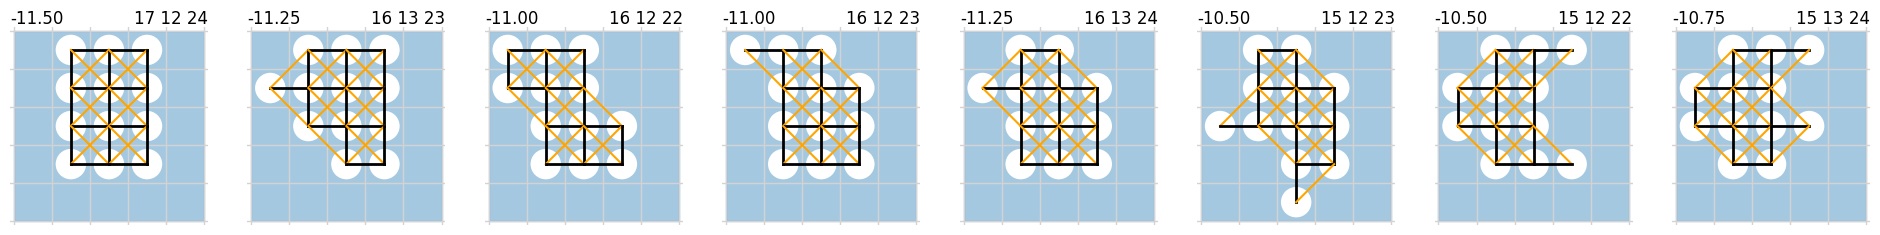

In [107]:
MicroState = make_microstate_factory(N=12, L=5, descriptor_method=descriptor_method_3bins)

opt_m = MicroState(mmc.opt_m.i)
mcc_markov = MonteCarlo(MicroState, opt_m, kT=0.3)
mcc_markov.run(100)

descriptors = []
descriptors_states = []

for state in mcc_markov.states:
    if state.descriptor not in descriptors:
        descriptors.append(state.descriptor)
        descriptors_states.append(state)
    if len(descriptors) >= 8:
        break

fig_length = len(descriptors)
fig, axes = plt.subplots(1, fig_length, figsize=(3*fig_length, 3))

print(descriptors)
for i, state in enumerate(descriptors_states):
    state.plot(axes[i], label='Dual')

### Task 4

Make a many-bins descriptor, and see how we can discriminate between same energies and three-bin descriptors when they are equal.

In [119]:
class ManyBinsDescriptor(DescriptorBase):

    centers = np.arange(1, 5, 0.5)
    ylim = [0, 25]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist, _ = np.histogram(dist_vector, self.edges)
        return hist.tolist()   # returns the bin counts

class ThreeBinsDescriptor(DescriptorBase):

    centers = [1, 1.5, 2]
    ylim = [0, 25]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist, _ = np.histogram(dist_vector, self.edges)
        return hist.tolist()   # returns the bin counts

Running MMC for 100 steps.
Optimal system energy: -11.5
[[17, 12, 24, 0, 11, 2, 0, 0], [16, 13, 23, 0, 12, 2, 0, 0], [16, 13, 24, 0, 11, 2, 0, 0], [16, 13, 24, 0, 12, 1, 0, 0], [16, 12, 24, 0, 12, 2, 0, 0]]


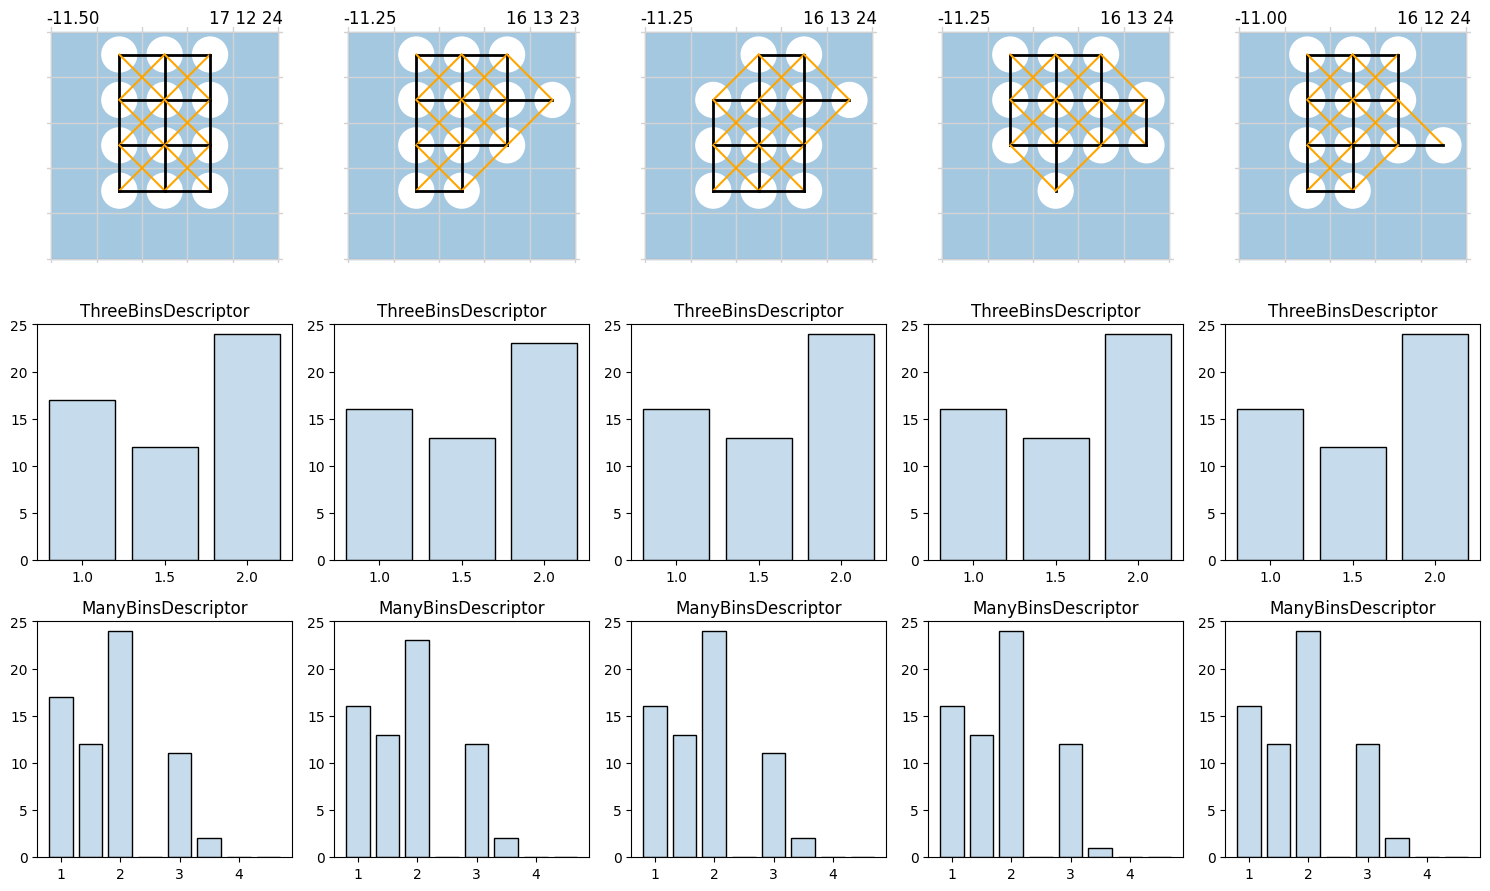

In [127]:
descriptor_method_many = ManyBinsDescriptor()
descriptor_method_3bins = ThreeBinsDescriptor()

MicroState = make_microstate_factory(N=12, L=5, descriptor_method=descriptor_method_many)

opt_m = MicroState(mmc.opt_m.i)
mcc_markov = MonteCarlo(MicroState, opt_m, kT=0.3)
mcc_markov.run(100)

descriptors = []
threebins_states = []
manybins_states = []

for state in mcc_markov.states:
    if state.descriptor not in descriptors:
        descriptors.append(state.descriptor)

        manybins_states.append(state)

        state = MicroState(state.i, descriptor_method=descriptor_method_3bins)
        threebins_states.append(state)

    if len(descriptors) >= 5:
        break

fig_length = len(descriptors)
fig, axes = plt.subplots(3, fig_length, figsize=(3*fig_length, 9))

print(descriptors)
for i, state in enumerate(threebins_states):
    state.plot(axes[0][i], label='Dual')
    state.plot_descriptor(axes[1][i])
for i, state in enumerate(manybins_states):
    state.plot_descriptor(axes[2][i])

fig.tight_layout()

We sometimes see that the three-bins descriptions are equal, but the many-bins descriptor differs.

# W07C - Smoothed pair-distance distribution

In [1]:
import numpy as np
import matplotlib .pyplot as plt
from scipy.spatial.distance import pdist
from scipy.special import erf
from week07 import make_microstate_factory, DescriptorBase

MicroState = make_microstate_factory(N=6, L=6)
m = MicroState(714762)

### Task 1 - ordinary histograms

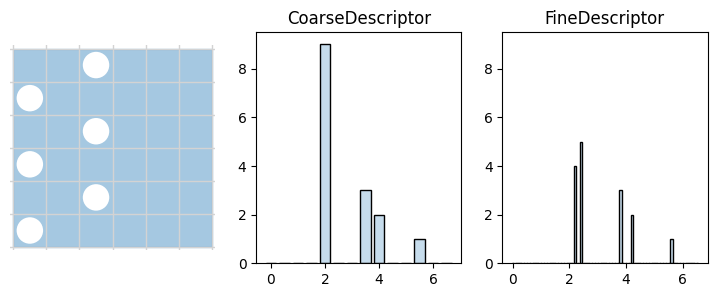

In [2]:
class CoarseDescriptor(DescriptorBase):
    centers = np.arange(0, 6.6, 0.5)
    ylim = [0, 9.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist, _ = np.histogram(dist_vector, self.edges)
        return hist.tolist()   # returns the bin counts
        
    
class FineDescriptor(CoarseDescriptor):
    centers = np.arange(0, 6.6, 0.1)

fig, axes = plt.subplots(1,3,figsize=(9,3))

cd = CoarseDescriptor()
fd = FineDescriptor()

m.plot(axes[0])
m = MicroState(m.i, descriptor_method=cd)
m.plot_descriptor(axes[1])
m = MicroState(m.i, descriptor_method=fd)
m.plot_descriptor(axes[2])

### Task 2 - sampling a Gaussian at the bin centers

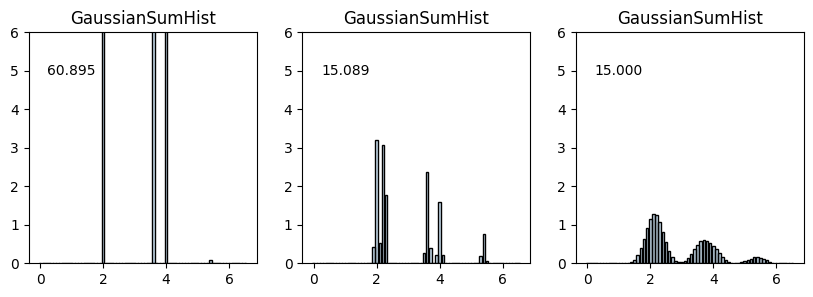

In [3]:
class GaussianSumHist(DescriptorBase):
    def __init__(self, *args, sigma=0.1, **kwargs):
        super().__init__ (*args, **kwargs)
        self.sigma = sigma

    centers = np.arange(0, 6.6, 0.1)
    ylim = [0, 6]

    def gaussian(self, r, ri, sigma):
        return 1/np.sqrt(2*np.pi)/sigma * np.exp(-(r-ri)**2/2/sigma**2)

    def __call__(self, pos):
        dx = 0.1
        dist_vector = pdist(pos)   # get the pairwise distances
        # for each value in centers, calculate the gaussian contribution.
        # far from pdist, low values. Close to pdist, larger values.
        gaussian_values = np.array([self.gaussian(self.centers, ri, self.sigma) for ri in dist_vector])
        hist = np.sum(gaussian_values, axis=0) * dx   # axis=0, only sum over rows, and get a list of sums.
        self.total = sum(hist)
        return hist.tolist()   # returns the bin counts


fig, axes = plt.subplots(1,3,figsize=(10,3))

for i, sigma in enumerate([0.005, 0.05, 0.25]):
    gaus = GaussianSumHist(sigma=sigma)
    m = MicroState(m.i, descriptor_method=gaus)
    m.plot_descriptor(axes[i])
    axes[i].text(1, 5, f'{gaus.total:.3f}', ha='center', va='center', size=10)
    

We see that if $\sigma<dx=0.1$, it is difficult to sample accurately, because the tail of the Gaussian is so small.

### Task 3

A consistent bin value is obtained by integrating each Gaussian over the full bin interval. Show that this gives:

$$g_j = \sum_i \frac{1}{2} \left[erf\left(\frac{x_j-r_i+\Delta x/2}{\sqrt{2}\sigma}\right)-erf\left(\frac{x_j-r_i-\Delta x/2}{\sqrt{2}\sigma}\right)\right]$$

and implement in a new descriptor class.

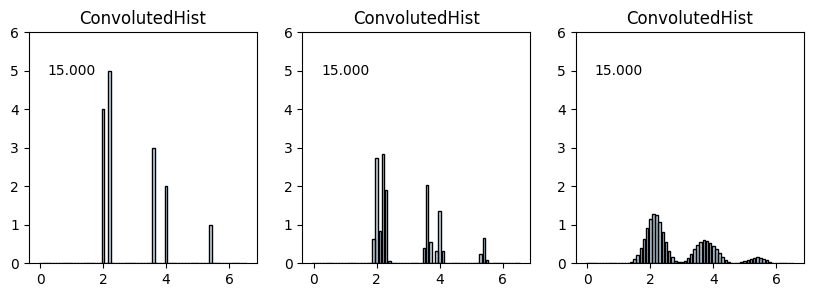

In [4]:
class ConvolutedHist(DescriptorBase):
    def __init__(self, *args, sigma=0.1, **kwargs):
        super().__init__ (*args, **kwargs)
        self.sigma = sigma

    centers = np.arange(0, 6.6, 0.1)
    ylim = [0, 6]

    def __call__(self, pos):
        dx = 0.1
        dist_vector = pdist(pos)
        erf_values = np.array([erf((self.centers-ri+dx/2)/np.sqrt(2)/self.sigma) \
                               - erf((self.centers-ri-dx/2)/np.sqrt(2)/self.sigma) \
                               for ri in dist_vector])
        hist = np.sum(1/2*erf_values, axis=0)   # axis=0, only sum over rows, and get a list of sums.
        self.total = sum(hist)
        return hist.tolist()   # returns the bin counts


fig, axes = plt.subplots(1,3,figsize=(10,3))

for i, sigma in enumerate([0.005, 0.05, 0.25]):
    erf_d = ConvolutedHist(sigma=sigma)
    m = MicroState(m.i, descriptor_method=erf_d)
    m.plot_descriptor(axes[i])
    axes[i].text(1, 5, f'{erf_d.total:.3f}', ha='center', va='center', size=10)

Why should the sum now be approximately 15?

Because we integrate each Gaussian over the full bin interval using the expression. A Gaussian is normalized, so integrating over it should give an area of 1, if the histogram range contains all relevant Gaussian tails. Then summing over all integrations is just $\sum_{i=1}^{15}1=15$

### Task 4

Move an atom continously through the configuration

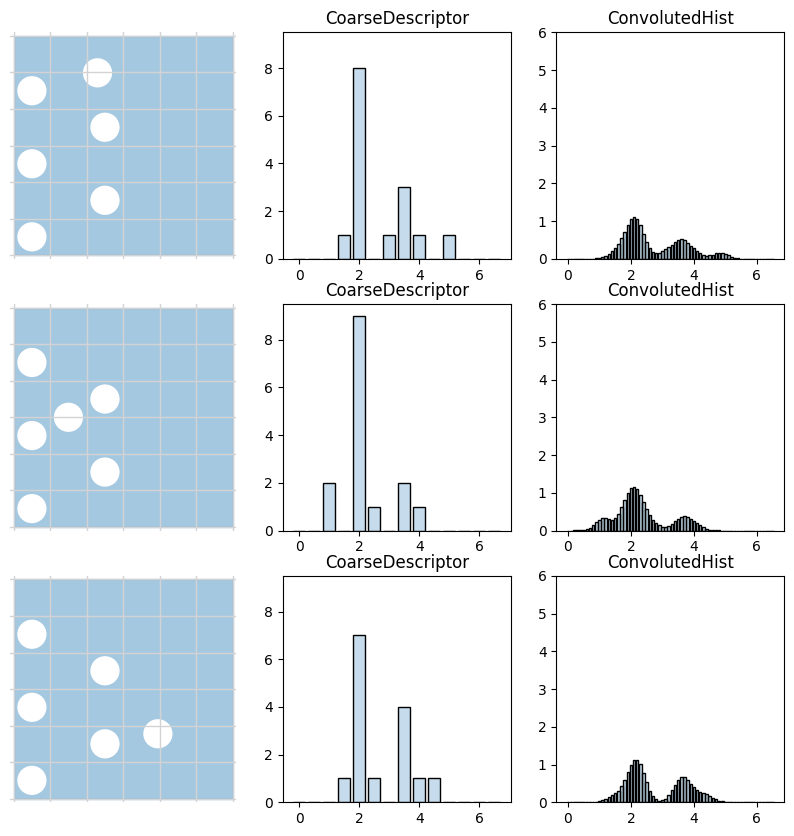

In [5]:
m = MicroState(714762)

xs = np.concatenate([np.linspace(m.pos[0][0], 1, 50), np.linspace(1, 4, 50)])
ys = np.concatenate([np.linspace(m.pos[0][1], 2.5, 50), np.linspace(2.5, 1, 50)])

fig, axes = plt.subplots(3,3,figsize=(10,10))

for row, idx in zip(axes, [10, 50, 90]):
    sigma = 0.25
    m.pos[0] = [xs[idx], ys[idx]]
    m.plot(row[0])

    coarse_d = CoarseDescriptor()
    erf_d = ConvolutedHist(sigma=sigma)

    m = MicroState(m.i, descriptor_method=coarse_d)
    m.pos[0] = [xs[idx], ys[idx]]
    m.plot_descriptor(row[1])

    m = MicroState(m.i, descriptor_method=erf_d)
    m.pos[0] = [xs[idx], ys[idx]]
    m.plot_descriptor(row[2])

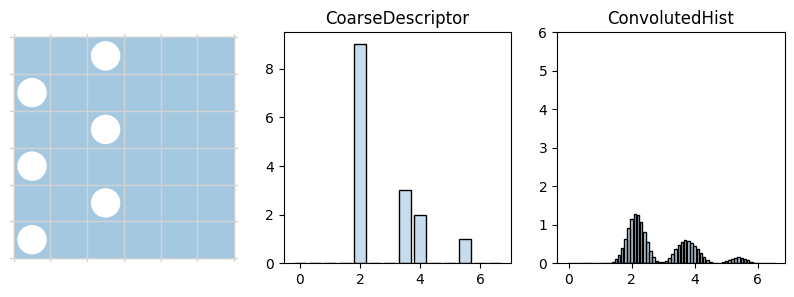

In [6]:
from matplotlib import animation
plt.rc('animation', html='jshtml')

m_coarse = MicroState(714762, descriptor_method=coarse_d)
m_conv = MicroState(714762, descriptor_method=erf_d)

fig, axes = plt.subplots(1,3,figsize=(10,3))

def draw_frame(idx):
    axes[0].clear()
    m_coarse.pos[0] = [xs[idx], ys[idx]]
    m_conv.pos[0] = [xs[idx], ys[idx]]
    
    m_coarse.plot(axes[0])
    m_coarse.plot_descriptor(axes[1])
    m_conv.plot_descriptor(axes[2])

draw_frame(0)



In [9]:
def update(i):
    draw_frame(i)

anim = animation.FuncAnimation(fig, update, frames=range(len(xs)), interval=50, blit=False)
writer = animation.writers['pillow'](fps=15) # frames per second
anim.save('W07C_convolutedhist.gif', writer=writer)
# anim

Notice how the distance between atoms reduces as the free atom moves in between the others, and how the distance increases as it moves away. I.e. there are more large pairwise distances when the free atom is far away, and more short pairwise distances when the free atom moves closer to the rest.

As the particle moves, the coarse descriptor makes abrupt jumps and doesn't distinguish between very fine position differences, while convoluted hist does.

<br>

Increasing sigma makes the distrubtions wider, and we may loose some information about the *actual* center, i.e. the actual distance between atoms.

Decreasing sigma makes the distribution more peaked around the centers, resembling the FineDescriptor, which would become sensitive to small changes. 

# W07D    CUR feature selection

In [10]:
import numpy as np
import matplotlib .pyplot as plt
from scipy.spatial.distance import pdist
from scipy.special import erf
from week07 import make_microstate_factory, DescriptorBase

Data matrix:
0.01 1.12 5.79 4.09 2.72 1.23 0.04 0.00 0.00
0.00 0.33 2.38 3.40 4.70 3.22 0.80 0.16 0.00
0.01 0.63 2.99 1.65 2.46 1.70 1.95 2.06 1.06
0.00 0.02 1.52 4.72 3.97 1.62 2.34 0.80 0.02


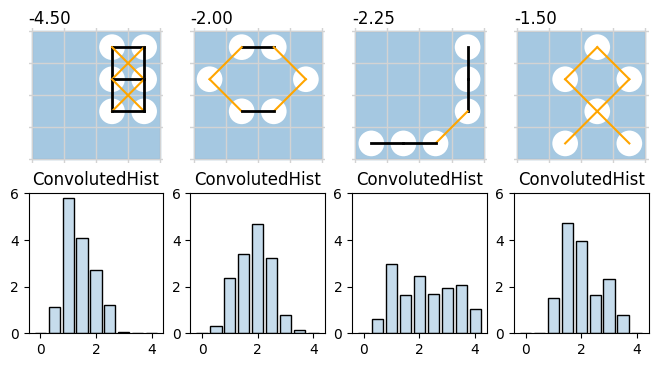

In [11]:
MicroState = make_microstate_factory(N=6, L=4)
i_vals = [5303, 3311, 7023, 5958]

class ConvolutedHist(DescriptorBase):

    centers = np.arange(0, 4.1, 0.5)
    ylim = [0, 6]
    sigma = 0.25

    def __call__(self, pos):
        dx = 0.5
        dist_vector = pdist(pos)
        erf_values = np.array([erf((self.centers-ri+dx/2)/np.sqrt(2)/self.sigma) \
                               - erf((self.centers-ri-dx/2)/np.sqrt(2)/self.sigma) \
                               for ri in dist_vector])
        hist = np.sum(1/2*erf_values, axis=0)   # axis=0, only sum over rows, and get a list of sums.
        self.total = sum(hist)
        return hist.tolist()   # returns the bin counts

fig, axes = plt.subplots(2,4,figsize=(8,4))
descriptor = ConvolutedHist()

data_matrix = []
for i, i_val in enumerate(i_vals):
    m = MicroState(i_val, descriptor_method=descriptor)
    m.plot(axes[0][i], label='Energy')
    m.plot_descriptor(axes[1][i])

    hist = descriptor(m.pos)
    data_matrix.append(hist)

print('Data matrix:')
for row in data_matrix:
    print(" ".join(f"{x:.2f}" for x in row))


A distance of 1 and 2 appear to be the two bins that vary the most, and may represent the structures the most.

That would be idx: 2 and 4

### Task 3

Centre every feature by subtracting its mean over the four configurations

$X_c = X - 1\mu^T$

Centering a matrix means that every coloumn has mean zero.

In [12]:
data_matrix = np.array(data_matrix)
centered_matrix = data_matrix - data_matrix.mean(axis=0)
print('Centered matrix:')
for row in centered_matrix:
    print(" ".join(f"{x:5.2f}" for x in row))

Centered matrix:
 0.01  0.59  2.62  0.62 -0.74 -0.71 -1.24 -0.75 -0.27
-0.00 -0.20 -0.79 -0.06  1.24  1.28 -0.48 -0.60 -0.27
 0.00  0.11 -0.18 -1.81 -1.00 -0.25  0.67  1.31  0.79
-0.00 -0.50 -1.65  1.25  0.50 -0.32  1.05  0.04 -0.25


### Task 4

Form the feature covariance matrix

$S=\frac{1}{N-1}X_c^T X_c$

where 𝑁 = 4. Use np.linalg.eigh to find its eigenvalues and eigenvectors, and sort them
in decreasing order of eigenvalue. Remember that np.linalg.eigh returns the eigenvectors as
columns. 

Verify both the eigenvalue equation for at least one eigenpair and the reconstruction.


In [13]:
N=4

cov_matrix = 1/(N-1) * centered_matrix.T @ centered_matrix

eigenvalues_S, eigenvectors_S = np.linalg.eigh(cov_matrix)

idx = np.argsort(eigenvalues_S)[::-1]   # Returns the indices that sorts the array in reverse order (high to low)
eigenvalues_S = eigenvalues_S[idx]
eigenvectors_S = eigenvectors_S[:, idx]   # get the eigenvectors_S (rows in matrix) from the same sorting

l = eigenvalues_S[0]
v = np.array(eigenvectors_S)[:, 0]

print('Eigenvalues:', *[f'{x:.2f},' for x in eigenvalues_S if x>1e-5])


print('\nRunning checks:')
check1 = cov_matrix @ v
print(" ".join(f"{x:5.2f}" for x in check1))
print('==')
check2 = l * v
print(" ".join(f"{x:5.2f}" for x in check2))


print('\nCovariance matrix S:')
for row in cov_matrix:
    print(" ".join(f"{x:5.2f}" for x in row))

reconstruction = eigenvectors_S @ np.diag(eigenvalues_S) @ eigenvectors_S.T
print('\nReconstruction of S:')
for row in reconstruction:
    print(" ".join(f"{x:5.2f}" for x in row))


Eigenvalues: 5.05, 3.19, 1.29,

Running checks:
-0.01 -1.01 -4.15 -0.05  1.44  0.96  1.91  0.76  0.11
==
-0.01 -1.01 -4.15 -0.05  1.44  0.96  1.91  0.76  0.11

Covariance matrix S:
 0.00  0.00  0.01 -0.00 -0.00 -0.00 -0.00 -0.00  0.00
 0.00  0.22  0.84 -0.15 -0.35 -0.18 -0.37 -0.07  0.03
 0.01  0.84  3.42 -0.02 -1.19 -0.77 -1.58 -0.60 -0.07
-0.00 -0.15 -0.02  1.75  0.64 -0.16 -0.21 -0.91 -0.63
-0.00 -0.35 -1.19  0.64  1.11  0.73  0.06 -0.49 -0.35
-0.00 -0.18 -0.77 -0.16  0.73  0.77 -0.08 -0.19 -0.09
-0.00 -0.37 -1.58 -0.21  0.06 -0.08  1.11  0.71  0.24
-0.00 -0.07 -0.60 -0.91 -0.49 -0.19  0.71  0.88  0.46
 0.00  0.03 -0.07 -0.63 -0.35 -0.09  0.24  0.46  0.28

Reconstruction of S:
 0.00  0.00  0.01 -0.00 -0.00 -0.00 -0.00 -0.00  0.00
 0.00  0.22  0.84 -0.15 -0.35 -0.18 -0.37 -0.07  0.03
 0.01  0.84  3.42 -0.02 -1.19 -0.77 -1.58 -0.60 -0.07
-0.00 -0.15 -0.02  1.75  0.64 -0.16 -0.21 -0.91 -0.63
-0.00 -0.35 -1.19  0.64  1.11  0.73  0.06 -0.49 -0.35
-0.00 -0.18 -0.77 -0.16  0.73  0.77 -0.08

*How many nonzero eigenvalues can this covariance matrix have, and why?*

Something about rank probably

### Task 5

Form the configuration Gram matrix

$G=\frac{1}{N-1} X_c X_c^T$

Diagonalize it, sort its eigenvalues in decreasing order, and denote its orthonormal eigenvectors
by the columns of U. Verify the reconstruction.

In [14]:
gram_matrix = 1/(N-1) * centered_matrix @ centered_matrix.T

print('\nGram matrix G:')
for row in gram_matrix:
    print(" ".join(f"{x:5.2f}" for x in row))

eigenvalues_G, eigenvectors_G = np.linalg.eigh(gram_matrix)

idx = np.argsort(eigenvalues_G)[::-1]   # Returns the indices that sorts the array in reverse order (high to low)
eigenvalues_G = eigenvalues_G[idx]
eigenvectors_G = eigenvectors_G[:, idx]   # get the eigenvectors_G (rows in matrix) from the same sorting


reconstruction = eigenvectors_G @ np.diag(eigenvalues_G) @ eigenvectors_G.T
print('\nReconstruction of G:')
for row in reconstruction:
    print(" ".join(f"{x:5.2f}" for x in row))


Eigenvalues = eigenvectors_G.T @ (gram_matrix @ eigenvectors_G)
print('\nEigenvalues, U.T @ (G @ U):')
for row in Eigenvalues:
    print(" ".join(f"{x:5.2f}" for x in row))



Gram matrix G:
 3.62 -0.98 -0.88 -1.75
-0.98  1.50 -0.88  0.36
-0.88 -0.88  2.39 -0.63
-1.75  0.36 -0.63  2.02

Reconstruction of G:
 3.62 -0.98 -0.88 -1.75
-0.98  1.50 -0.88  0.36
-0.88 -0.88  2.39 -0.63
-1.75  0.36 -0.63  2.02

Eigenvalues, U.T @ (G @ U):
 5.05 -0.00  0.00  0.00
-0.00  3.19 -0.00  0.00
 0.00 -0.00  1.29  0.00
 0.00  0.00  0.00  0.00


*Compare the nonzero eigenvalues of G with those of S. Explain why they are the same although
the two matrices have different dimensions.*

Changing the dimensions changes the number of zero eigenvalues, but not the number of nonzero eigenvalues.

It follows from linear algebra that $AB$ and $BA$ have the same nonzero eigenvalues? Something about SVD?

### Task 6

For every strictly positive eigenvalue, use the right singular vectors to construct the corresponding
left singular vector from

$X_c \nu_\alpha = \sigma_\alpha u_\alpha, \qquad \sigma_\alpha = \sqrt{(N-1)\lambda_\alpha}$

Compare the vectors obtained in this way with the eigenvectors of G. Recall that an eigenvector
is only determined up to an overall sign. Do not divide by $\sigma_\alpha$ for a zero eigenvalue.

In [15]:
eigenvalues_S = eigenvalues_S[eigenvalues_S > 1e-5]

sigma = np.sqrt((N-1)*eigenvalues_S)
U = np.zeros((N, N))
for i in range(len(eigenvalues_S)):
    U[:,i] = centered_matrix @ eigenvectors_S[:,i] / sigma[i]  # add as coloumns

# Now compare the vectors with the eigenvectors of G

print('\nEigenvectors of G:')
for row in eigenvectors_G:
    print(" ".join(f"{x:5.2f}" for x in row))

print('\nU derived from V:')
for row in U:
    print(" ".join(f"{x:5.2f}" for x in row))


Eigenvectors of G:
-0.83  0.21  0.16  0.50
 0.26  0.38 -0.73  0.50
 0.07 -0.86 -0.08  0.50
 0.49  0.27  0.66  0.50

U derived from V:
-0.83  0.21  0.16  0.00
 0.26  0.38 -0.73  0.00
 0.07 -0.86 -0.08  0.00
 0.49  0.27  0.66  0.00


Collect the singular values in $\Sigma$ and reconstruct the centred data matrix from

$X_c = U \Sigma V^T$

Use only singular-vector triplets associated with nonzero singular values. Check the reconstruction numerically against the original centred matrix. If you combine U and V obtained from
separate diagonalizations, account for the possible independent sign choices of corresponding
eigenvectors.

In [16]:
# to construct a 4x9 matrix, we must have U being a 4x4, Sigma being a 4x9 and V^T being a 9x9

sigma = np.sqrt((N-1)*eigenvalues_S)
sigma=np.concatenate([sigma, [0]])  # to make a NxN matrix (4x4)
Sigma = np.zeros((N, 9))  # d=9
np.fill_diagonal(Sigma, sigma)

recon_centered_matrix = U @ Sigma @ eigenvectors_S.T
print('\nCentered matrix X_c:')
for row in centered_matrix:
    print(" ".join(f"{x:5.2f}" for x in row))

print('\nReconstruction of X_c through SVD:')
for row in recon_centered_matrix:
    print(" ".join(f"{x:5.2f}" for x in row))


Centered matrix X_c:
 0.01  0.59  2.62  0.62 -0.74 -0.71 -1.24 -0.75 -0.27
-0.00 -0.20 -0.79 -0.06  1.24  1.28 -0.48 -0.60 -0.27
 0.00  0.11 -0.18 -1.81 -1.00 -0.25  0.67  1.31  0.79
-0.00 -0.50 -1.65  1.25  0.50 -0.32  1.05  0.04 -0.25

Reconstruction of X_c through SVD:
 0.01  0.59  2.62  0.62 -0.74 -0.71 -1.24 -0.75 -0.27
-0.00 -0.20 -0.79 -0.06  1.24  1.28 -0.48 -0.60 -0.27
 0.00  0.11 -0.18 -1.81 -1.00 -0.25  0.67  1.31  0.79
-0.00 -0.50 -1.65  1.25  0.50 -0.32  1.05  0.04 -0.25


### Task 8

Reduce the descriptor from nine features to two 

In [19]:
# Evaluating coloumn leverage:

k = 2
# eigenvectors shape (9,9)
V_k = eigenvectors_S[:, :k]          # shape (9, 2), take coordinates from two largest eigenvectors

leverage = np.sum(V_k**2, axis=1)    # shape (9, 1)

print(" ".join(f"{x:.3f}" for x in leverage))

0.000 0.044 0.677 0.419 0.263 0.059 0.198 0.256 0.086


In task 1 I judged that pairwise distances of 1 and 2, idx 2 and 4, appeared most informative.

The leverage score indicates that the more informative features are pairwise distances of 1 and 1.5, idx 2 and 3.

In [20]:
# calculate the fraction of the total centred-data variance contianed directly in the selected columns
total_variance = np.linalg.norm(centered_matrix)
variance_idx2 = np.linalg.norm(centered_matrix[:, 2])**2/total_variance**2
print(variance_idx2)
variance_idx3 = np.linalg.norm(centered_matrix[:, 3])**2/total_variance**2
print(variance_idx3)
tot_fractional_variance = variance_idx2 + variance_idx3
print('Fraction of the total centred-data variance contained in the selected columns (idx 2 and 3): ' + f'{tot_fractional_variance:.3f}')

0.35882835587999623
0.18355230049934124
Fraction of the total centred-data variance contained in the selected columns (idx 2 and 3): 0.542


The leverage and variance contained in individually selected coloumns measure related properties. Leverage scores and column variance both say something about how "important" a column is.

Leverage score $\ell_i = \sum_{\alpha=1}^{k} V_{i\alpha}^2$ measures how much column $i$ points into the top-$k$ right singular subspace. It is the squared length of the projection of the $i$-th unit coordinate vector $e_i$ onto that subspace.

Column variance $\|X_c[:, i]\|^2/\|X_c\|_F^2 = C_{ii}/\mathrm{tr}(C)$ measures the size of column $i$, i.e. how spread out that feature is. It depends on the units and scale of the feature and ignores the subspace structure entirely.

### Task 9

Plot the four configurations in each of the two reduced, two-dimensional representations

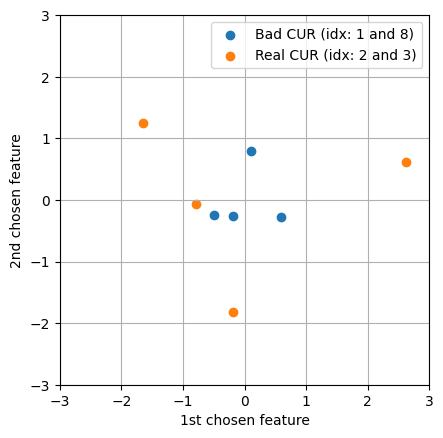

In [94]:
fig, ax = plt.subplots()
real_xs = []; real_ys = []
heuristic_xs = []; heuristic_ys = []
for row in centered_matrix:
    real_xs.append(row[2])
    real_ys.append(row[3]) 
    heuristic_xs.append(row[1])
    heuristic_ys.append(row[8])

ax.scatter(heuristic_xs, heuristic_ys, c='C0', label='Bad CUR (idx: 1 and 8)')
ax.scatter(real_xs, real_ys, c='C1', label='Real CUR (idx: 2 and 3)')
ax.set_xlim(-3,3)
ax.set_ylim(-3,3)
ax.set_xlabel('1st chosen feature')
ax.set_ylabel('2nd chosen feature')
ax.grid()
ax.set_aspect('equal')
ax.legend()


Noter fra bjørk:

Hvad sker der når vi vælger vores features ud fra CUR?

Heuristisk kan vi komme med et bud på hvad de vigtigste features er. Heuristisk går ud på at vælge dem der varierer mest, f.eks. ved at sammenligne maximum og minimum i forskellige fordelinger.

Vi havde et 9D feature rum og gik over til et 2D feature rum - Der var 9 bins, vi gik over til at vise det i et 2D plot.

For at lave et godt bud frem for heuristisk, vi laver coloumn leverage form.
 
Vi skal centrerer det for at variancen ikke ligger omkring nulpunktet (de bliver store uden god grund), men i stedet ligge dem omkring middelvægten.

$S=V\Lambda V^T  \Rightarrow V^T S V = V^T V \Lambda V^T V = \Lambda$ 9x9 matrix

$G=U\Gamma U^T$ 4x4 matrix, med samme egenværdier, det var den aha oplevelse man skulle have

Når man centrerer fjerner man en frihedsgrad mister vi en egenværdi når vi centrerer. Det er et eksamensspørgsmål. Se billede fra forelæsning.

Vi fandt $X_c$, fik $V$, fandt $U$, og så kan vi rekonstruere med $X_c=U \Sigma V^T$

<br>

Når vi vælger dimension k=2, så kigger på de to egenvektorer med størst egenværdi. Inden for de eigenvektorer, som spænder over 9 features, vælger vi de koordinater der er størst mulige i det 9 dimensionelle feature rum.

I PCA tager vi linarkombinationen. Her drejer vi rummet for at gøre variancen størst mulig, det gør vi ikke i CUR, der er vi bundet til at vælge mellem de originale features.

# W07E  Principal Component Analysis

In [25]:
from week07 import make_microstate_factory, DescriptorBase
from scipy.spatial.distance import pdist
import numpy as np
import matplotlib.pyplot as plt

class TwoBinsDescriptor(DescriptorBase):
    centers = [1, 1.5]
    ylim = [0, 4.5]
    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram (dist_vector , self.edges)
        return hist [0].tolist()
    
descriptor_method_2d = TwoBinsDescriptor()

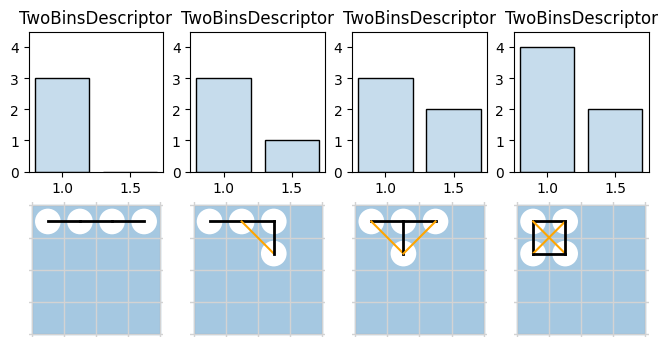

In [26]:
MicroState = make_microstate_factory(N=4, L=4)

i_vals = [0, 3, 2, 25]
fig, axes = plt.subplots(2,4,figsize=(8,4))

for i, i_val in enumerate(i_vals):
    m = MicroState(i_val, descriptor_method=descriptor_method_2d)
    m.plot(axes[1][i])
    m.plot_descriptor(axes[0][i])

In [27]:
def construct_sample_2d(config):
    assert len(config) == 8
    m_blue = MicroState(0, descriptor_method=descriptor_method_2d)
    m_orange = MicroState(3, descriptor_method=descriptor_method_2d)
    m_green = MicroState(2, descriptor_method=descriptor_method_2d)
    m_red = MicroState(25, descriptor_method=descriptor_method_2d)
    data_matrix_X = np.zeros((8,2))
    for i, e in enumerate(config):
        if e=='blue' or e=='b':
            data_matrix_X[i, :] = descriptor_method_2d(m_blue.pos)  # [3, 0]
        elif e=='orange' or e=='o':
            data_matrix_X[i, :] = descriptor_method_2d(m_orange.pos) # [3, 1]
        elif e=='green' or e=='g':
            data_matrix_X[i, :] = descriptor_method_2d(m_green.pos) # [3, 2]
        elif e=='red' or e=='r':
            data_matrix_X[i, :] = descriptor_method_2d(m_red.pos)   # [4, 2]
        else:
            return NameError
    return data_matrix_X

occurences = ['o']*2 + ['g']*5 + ['r']*1
print(occurences)
data_matrix_X = construct_sample_2d(occurences)
data_matrix_X

['o', 'o', 'g', 'g', 'g', 'g', 'g', 'r']


array([[3., 1.],
       [3., 1.],
       [3., 2.],
       [3., 2.],
       [3., 2.],
       [3., 2.],
       [3., 2.],
       [4., 2.]])

In [28]:
centered_matrix_Xc = data_matrix_X - data_matrix_X.mean(axis=0)
centered_matrix_Xc

array([[-0.125, -0.75 ],
       [-0.125, -0.75 ],
       [-0.125,  0.25 ],
       [-0.125,  0.25 ],
       [-0.125,  0.25 ],
       [-0.125,  0.25 ],
       [-0.125,  0.25 ],
       [ 0.875,  0.25 ]])

In [29]:
N=8   # number of observations
cov_matrix_C = 1/(N-1) * centered_matrix_Xc.T @ centered_matrix_Xc
for row in cov_matrix_C:
    print(" ".join(f"{x:5.3f}" for x in row))

0.125 0.036
0.036 0.214


In [30]:
eigenvalues_C, eigenvectors_C = np.linalg.eigh(cov_matrix_C)

idx = np.argsort(eigenvalues_C)[::-1]   # Returns the indices that sorts the array in reverse order (high to low)
eigenvalues_C = eigenvalues_C[idx]
eigenvectors_C = eigenvectors_C[:, idx]   # get the eigenvectors_S (rows in matrix) from the same sorting

print('Eigenvalues:\n', " ".join(f"{x:5.3f}" for x in eigenvalues_C))

print('\nEigenvectors:')
for row in eigenvectors_C:
    print(" ".join(f"{x:5.3f}" for x in row ))

Eigenvalues:
 0.227 0.112

Eigenvectors:
0.331 -0.944
0.944 0.331


### Task 6

Transform the centered data from the original descriptor space into the PCA space.

In [31]:
Z = centered_matrix_Xc @ eigenvectors_C
for row in Z:
    print(" ".join(f"{x:6.3f}" for x in row ))

-0.749 -0.130
-0.749 -0.130
 0.195  0.201
 0.195  0.201
 0.195  0.201
 0.195  0.201
 0.195  0.201
 0.526 -0.743


Each row still corresponds to one configuration, while the columns now correspond to principal
components

### Task 7

Keep only the first principal component and thereby reduce the descriptor from two features to
one.

In [32]:
Z_1feature = Z[:, :1]
for row in Z_1feature:
    print(" ".join(f"{x:6.3f}" for x in row))

-0.749
-0.749
 0.195
 0.195
 0.195
 0.195
 0.195
 0.526


### Task 8

Implement PCA in a class

In [33]:
class PCA:
    def __init__(self, n_components):
        self.n_components = n_components

    def fit(self, X):
        X = np.array(X)
        N = X.shape[0]  # number of observations/configurations
        self.mean = X.mean(axis=0)
        Xc = X - self.mean
        C = 1/(N-1) * Xc.T @ Xc

        eigenvalues_C, eigenvectors_C = np.linalg.eigh(C)
        idx = np.argsort(eigenvalues_C)[::-1]   # Returns the indices that sorts the array in reverse order (high to low)
        eigenvalues_C = eigenvalues_C[idx]
        eigenvectors_C = eigenvectors_C[:, idx]   # get the eigenvectors_S (rows in matrix) from the same sorting
        self.components = eigenvectors_C[:, :self.n_components]   # n principle components 
         
    def transform (self, X):
        Xc = X - self.mean
        Z = Xc @ self.components
        return Z

In [34]:
pca = PCA(1)
X = [[3, 1],
    [3, 1],
    [3, 2],
    [3, 2],
    [3, 2],
    [3, 2],
    [3, 2],
    [4, 2]]
pca.fit(X)
pca.transform(X)

array([[-0.74909711],
       [-0.74909711],
       [ 0.19453121],
       [ 0.19453121],
       [ 0.19453121],
       [ 0.19453121],
       [ 0.19453121],
       [ 0.52553815]])

### Task 9

Plot original space vs PCA space

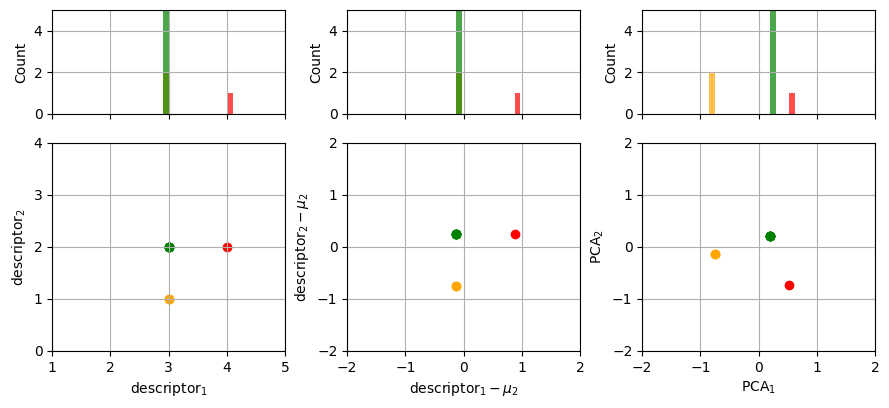

In [44]:
def plot_space(axes, occurences):
    top, bot = axes
    X = construct_sample_2d(occurences)
    X = np.array(X)
    for (x,y), c in zip(X, occurences):
        bot[0].scatter(x, y, color=c)

    pca = PCA(2)
    pca.fit(X)
    Xc = X - pca.mean
    for (x,y), c in zip(Xc, occurences):
        bot[1].scatter(x, y, color=c)

    Z=pca.transform(X)
    for (x,y), c in zip(Z, occurences):
        bot[2].scatter(x, y, color=c)

    # from chatbot
    for i, data in enumerate([X[:, 0], Xc[:, 0], Z[:, 0]]):
        for color in set(occurences):
            values = data[np.array(occurences) == color]
            top[i].hist(
                values,
                bins=np.arange(values.min() - 0.5, values.max() + 0.5 + 1, 0.1),
                color=color,
                alpha=0.7
            )

    # formatting
    for row in top:
        row.set_ylim(0,5)
        row.set_ylabel('Count')

    bot[0].set_ylabel(r'descriptor$_2$')
    bot[0].set_xlabel(r'descriptor$_1$')
    bot[1].set_ylabel(r'descriptor$_2 - \mu_2$')
    bot[1].set_xlabel(r'descriptor$_1 - \mu_2$')
    bot[2].set_ylabel(r'PCA$_2$')
    bot[2].set_xlabel(r'PCA$_1$')

    bot[0].set_ylim(0,4)
    bot[1].set_ylim(-2,2)
    bot[2].set_ylim(-2,2)

    bot[0].set_xlim(1,5)
    bot[1].set_xlim(-2,2)
    bot[2].set_xlim(-2,2)

    for ax in axes.flatten():
        ax.grid()


fig, axes = plt.subplots(2,3,figsize=(9,4), gridspec_kw={"height_ratios": [1, 2]}, sharex='col')

fig.tight_layout()

occurences = ['orange']*2 + ['green']*5 + ['red']
plot_space(axes, occurences)

Pointen med opgaven her er at vi bruger SVD til at finde PCA linjen (principal aksen) som maksimerer variansen, når vi har taget højde for vægten (centretet matricen).

Noter fra bjørk:

Vi vælger V0, da den har størst retning, så vi projecterer bare ned på V0 (Z).

Vi drejer den med V som egentlig er en rotationsmatrice

PCA_1 er den retning hvor vi spreder mest, størst varians.

Hvorfor vil man nogen gange lave CUR når det er bedre med PCA? Det er fordi vi trods alt stadig kan *se* hvad der vigtigt. I PCA laver den linearkombination af det, og så skal man ind og se hvad den har valgt af vigtige features

<br>

Egenværdien ER covariancen, så vi vælger egenvektoren(e) med størst(e) egenværdi(er). Så projekterer vi $X_c$ ned på $V$, således at vi får $Z$. Dermed får vi en linarkombination af de vigtigste features.

### Task 10

Choose other data sets made from the four microstates

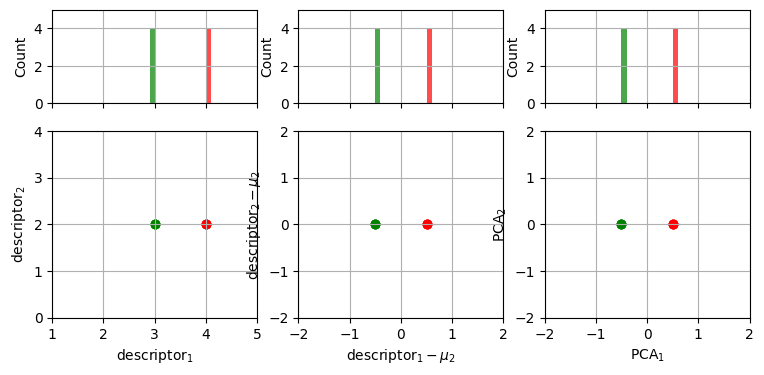

In [45]:
fig, axes = plt.subplots(2,3,figsize=(9,4), gridspec_kw={"height_ratios": [1, 2]}, sharex='col')
occurences = ['red']*4 + ['green']*4
plot_space(axes, occurences)

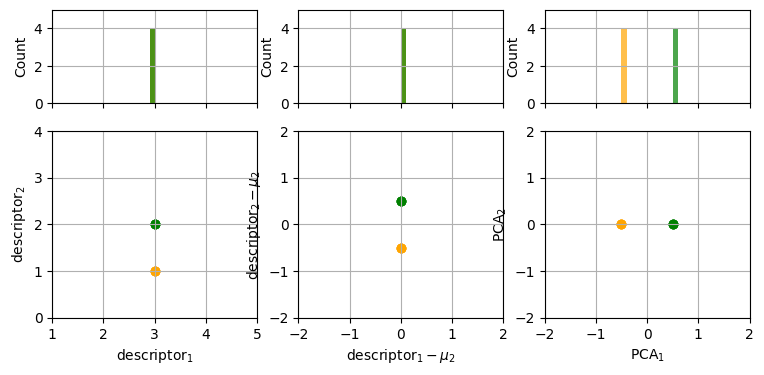

In [46]:
fig, axes = plt.subplots(2,3,figsize=(9,4), gridspec_kw={"height_ratios": [1, 2]}, sharex='col')
occurences = ['orange']*4 + ['green']*4
plot_space(axes, occurences)

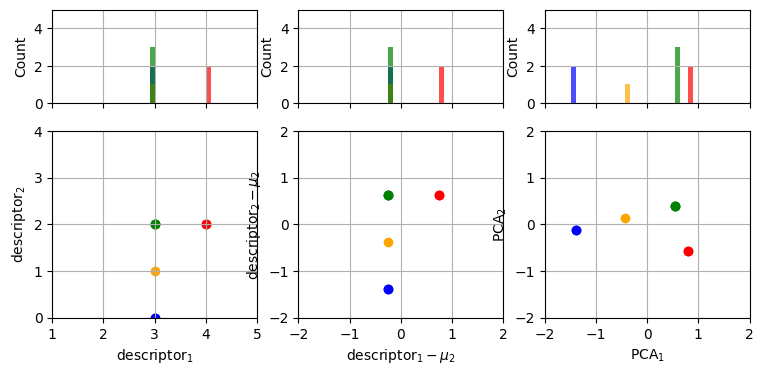

In [47]:
fig, axes = plt.subplots(2,3,figsize=(9,4), gridspec_kw={"height_ratios": [1, 2]}, sharex='col')
occurences = ['orange']*1 + ['green']*3 + ['red']*2 + ['blue']*2
plot_space(axes, occurences)

# W07F PCA and library implementations

In Exercise W07D we reduced a nine-feature descriptor to two selected original features using CUR. 

In this exercise we will instead use PCA to construct two new features as linear combinations of all nine original features, not just two.

We will consider the data matrix $X$ from W07D

In [42]:
import numpy as np
import matplotlib .pyplot as plt
from scipy.spatial.distance import pdist
from scipy.special import erf
from week07 import make_microstate_factory, DescriptorBase

Data matrix:
0.01 1.12 5.79 4.09 2.72 1.23 0.04 0.00 0.00
0.00 0.33 2.38 3.40 4.70 3.22 0.80 0.16 0.00
0.01 0.63 2.99 1.65 2.46 1.70 1.95 2.06 1.06
0.00 0.02 1.52 4.72 3.97 1.62 2.34 0.80 0.02


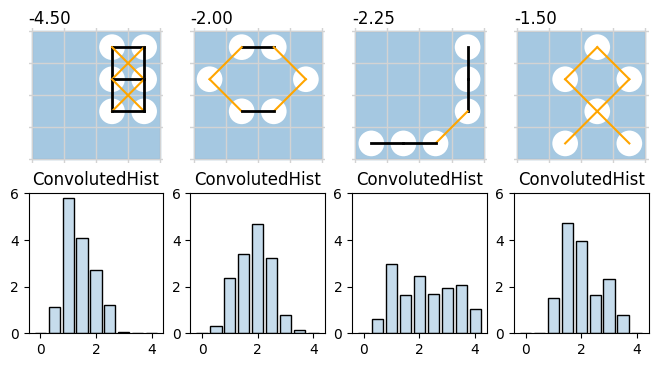

In [44]:
MicroState = make_microstate_factory(N=6, L=4)
i_vals = [5303, 3311, 7023, 5958]

class ConvolutedHist(DescriptorBase):

    centers = np.arange(0, 4.1, 0.5)
    ylim = [0, 6]
    sigma = 0.25

    def __call__(self, pos):
        dx = 0.5
        dist_vector = pdist(pos)
        erf_values = np.array([erf((self.centers-ri+dx/2)/np.sqrt(2)/self.sigma) \
                               - erf((self.centers-ri-dx/2)/np.sqrt(2)/self.sigma) \
                               for ri in dist_vector])
        hist = np.sum(1/2*erf_values, axis=0)   # axis=0, only sum over rows, and get a list of sums.
        self.total = sum(hist)
        return hist.tolist()   # returns the bin counts

fig, axes = plt.subplots(2,4,figsize=(8,4))
descriptor = ConvolutedHist()

X = []
for i, i_val in enumerate(i_vals):
    m = MicroState(i_val, descriptor_method=descriptor)
    m.plot(axes[0][i], label='Energy')
    m.plot_descriptor(axes[1][i])

    hist = descriptor(m.pos)
    X.append(hist)

print('Data matrix:')
for row in X:
    print(" ".join(f"{x:.2f}" for x in row))


### Task 1

PCA of the W07D data matrix

In [45]:
class PCA:
    def __init__(self, n_components):
        self.n_components = n_components

    def fit(self, X):
        X = np.array(X)
        N = X.shape[0]  # number of observations/configurations
        self.mean = X.mean(axis=0)
        Xc = X - self.mean
        C = 1/(N-1) * Xc.T @ Xc

        eigenvalues_C, eigenvectors_C = np.linalg.eigh(C)
        idx = np.argsort(eigenvalues_C)[::-1]   # Returns the indices that sorts the array in reverse order (high to low)
        eigenvalues_C = eigenvalues_C[idx]
        eigenvectors_C = eigenvectors_C[:, idx]   # get the eigenvectors_S (rows in matrix) from the same sorting
        self.components = eigenvectors_C[:, :self.n_components]   # n principle components 
         
    def transform (self, X):
        Xc = X - self.mean
        Z = Xc @ self.components
        return Z

In [46]:
# Fit PCA model to uncentered data matrix
pca = PCA(n_components=2)
pca.fit(X)
Z_PCA = pca.transform(X)

print('Check shape:', Z_PCA.shape)

# Let's compute the fraction of the total centred-data variance 
# retained by the two principal components.
Xc = X-pca.mean
total_variance = np.linalg.norm(Xc)
Z_PCA_variance = np.linalg.norm(Z_PCA)**2/total_variance**2
print(f'Total centred-data variance retained by the two principal components: {Z_PCA_variance:.3f}')

Check shape: (4, 2)
Total centred-data variance retained by the two principal components: 0.865


Discuss why this does not mean that PCA is always better than CUR. PCA is free to form linear
combinations of all nine original features, whereas CUR retains actual descriptor components
and therefore preserves their direct physical interpretation.

Hvorfor vil man nogen gange lave CUR når det er bedre med PCA? Det er fordi vi trods alt stadig kan *se* hvad der vigtigt. I PCA laver den linearkombination af det, og så skal man ind og se hvad den har valgt af vigtige features. I et mange dimensionelt rum bliver det svært at se hvilke features en ML model har valgt som vigtige, mens vi med CUR kan direkte udplukke de valgte features, som stemmer overens med de originale, og se hvad der er vurderet som vigtig.

*Eksempel fra Bjørk: Det kunne være at en feature der beskriver energien af et molekyle har stor betydning (giver stor 'retained variance'), mens at en feature der beskriver position er mindre vigtig. Det kan være nemmere at SE i CUR.*

### Task 2

In [6]:
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA as SklearnPCA

In [51]:
svd = TruncatedSVD ( n_components =2, random_state =0)
svd.fit(Xc)
V_k = svd.components_.T
leverage_scores = np.sum(V_k **2, axis =1)  # print these and check
                                            # against W07D

print(" ".join(f"{x:5.3f}" for x in sorted(leverage_scores)[::-1]))  # they are the same, thankfully
idx = np.argsort(leverage_scores)[::-1] 
print('2 largest leverage_score idx:', idx[:2])

# YOUR CODE HERE ( involving entries (rows or columns ?) of Xc with highest leverage scores)
Z_CUR = Xc[:, idx[:2]]
print('\nCheck Z shapes:')
print('Z_CUR shape:', Z_CUR.shape)

pca_sklearn = SklearnPCA(n_components=2)
pca_sklearn.fit(X)
Z_PCA_sklearn = pca_sklearn.transform(X)
print('Z_PCA_sklearn shape:', Z_PCA_sklearn.shape)

print('\nContained variance by PCA sklearn:', pca_sklearn.explained_variance_ratio_, sum(pca_sklearn.explained_variance_ratio_))
print('Matches Task 1.\n')

print('\nPrinciple directions by PCA class:')
for row in pca.components.T:
    print(" ".join(f"{x:6.3f}" for x in row))

print('\nPrinciple directions by PCA sklearn:')
for row in pca_sklearn.components_:
    print(" ".join(f"{x:6.3f}" for x in row))


0.677 0.419 0.263 0.256 0.198 0.086 0.059 0.044 0.000
2 largest leverage_score idx: [2 3]

Check Z shapes:
Z_CUR shape: (4, 2)
Z_PCA_sklearn shape: (4, 2)

Contained variance by PCA sklearn: [0.53014147 0.33491455] 0.8650560232686727
Matches Task 1.


Principle directions by PCA class:
-0.002 -0.200 -0.822 -0.010  0.286  0.191  0.377  0.150  0.022
-0.001 -0.058 -0.015  0.647  0.425  0.151 -0.236 -0.483 -0.292

Principle directions by PCA sklearn:
 0.002  0.200  0.822  0.010 -0.286 -0.191 -0.377 -0.150 -0.022
-0.001 -0.058 -0.015  0.647  0.425  0.151 -0.236 -0.483 -0.292


It is important to give a centered matrix to SVD, otherwise we would include variation around the mean, which is in most cases not what we are interested in when looking at the variance.

Interestingly, PCA_1 differs between scikit-learn PCA and my class PCA. This is simply just that the vector points in the opposite direction, it has no physical *size*. It's like flipping the axis.

### Task 3

Inspect how the two directions chosen by PCA lie in the original feature space. 

Can you recognize numerically large coefficients on original descriptor features known to be
important from SVD-informed CUR?

In [53]:
print('\nPrinciple directions by PCA sklearn:')
for row in pca_sklearn.components_:
    print(" ".join(f"{x:6.3f}" for x in row))


Principle directions by PCA sklearn:
 0.002  0.200  0.822  0.010 -0.286 -0.191 -0.377 -0.150 -0.022
-0.001 -0.058 -0.015  0.647  0.425  0.151 -0.236 -0.483 -0.292


We know from SVD-informed CUR that idx [2, 3] are the important.

Looking at PCA_1, idx=2 has the largest numerical coefficient.

Looking at PCA_2, idx=3 has the largest numerical coefficient.

Thus PCA also weigh these features highly.


### Task 4

Compare the CUR and PCA coordinate spaces